# Experiment 4: Uncertainty Quantification & Post-Hoc Probability Calibration Under Domain Shift

**Clinical Safety Focus:**  
Evaluating whether predicted probabilities reflect genuine empirical risk of **Muscle-Invasive Bladder Cancer (MIBC)** and developing post-hoc calibration strategies (**Temperature Scaling**, **Platt Scaling**, **Isotonic Regression**, **Monte Carlo Dropout**) to safeguard clinical decision support.

---

## 1. Clinical Rationale: Why Calibration Is as Critical as Accuracy

In radiological oncology, machine learning models do not merely produce binary labels; their continuous output probabilities $\hat{p} \in [0, 1]$ directly inform clinical risk stratification:
* A patient with an estimated $p(\text{MIBC}) = 0.95$ is referred for staging pelvic lymphadenectomy and neoadjuvant chemotherapy.
* A patient with $p(\text{MIBC}) = 0.52$ is in an ambiguous diagnostic grey zone requiring multidisciplinary tumor board review, repeat cystoscopy, or biopsy.

If a deep learning model suffers from **overconfidence under domain shift** (e.g., outputting $0.98$ confidence on an out-of-distribution scanner slice that is actually NMIBC), clinical triage fails catastrophically.

---

## 2. Mathematical Formulation of Calibration Metrics

### 2.1 Expected Calibration Error (ECE)
Partition all test predictions into $M$ equal-width confidence bins $B_1, B_2, \dots, B_M$:
$$\text{ECE} = \sum_{m=1}^{M} \frac{|B_m|}{N} \left| \text{acc}(B_m) - \text{conf}(B_m) \right|$$
where $\text{acc}(B_m) = \frac{1}{|B_m|} \sum_{i \in B_m} \mathbf{1}(y_i = \hat{y}_i)$ and $\text{conf}(B_m) = \frac{1}{|B_m|} \sum_{i \in B_m} \hat{p}_i$.

### 2.2 Brier Score
Strictly proper scoring rule measuring probability accuracy:
$$\text{Brier} = \frac{1}{N} \sum_{i=1}^{N} (\hat{p}_i - y_i)^2$$

---

## 3. Post-Hoc Calibration Methods Evaluated
1. **Uncalibrated Baseline Logits (Raw Softmax):** $\hat{p} = \sigma(z)$.
2. **Temperature Scaling (Guo et al., ICML 2017):** $\hat{p} = \sigma(z / T)$ where scalar $T > 0$ is optimized via NLL on validation logits. Preserves AUROC and ranking perfectly while softening overconfidence.
3. **Platt Scaling (Logistic Calibration):** $\hat{p} = \sigma(a z + b)$ with two learnable affine parameters.
4. **Isotonic Regression:** Non-parametric piecewise constant isotonic mapping $\hat{p} = g(z)$.
5. **Monte Carlo Dropout (Gal & Ghahramani):** Epistemic uncertainty estimated via stochastic forward passes at test time.


In [1]:
# ==============================================================================
# Cell 1: Environment Setup & Deterministic Configuration
# ==============================================================================
import os
import re
import time
import random
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score, brier_score_loss, log_loss
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')

RANDOM_SEED = 42
def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(RANDOM_SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print(f"Device: {device} | Deterministic Seed = 42")


Device: cpu | Deterministic Seed = 42


In [2]:
# ==============================================================================
# Cell 2: Dataset Loading & MD5 Deduplication
# ==============================================================================
DATA_DIR = Path('dataset')

def calc_md5(fp):
    h = hashlib.md5()
    with open(fp, 'rb') as f:
        for chunk in iter(lambda: f.read(4096), b''):
            h.update(chunk)
    return h.hexdigest()

# -----------------------------------------------------------------------------
# Canonical cross-platform path parser (validated on the official Kaggle
# release, all 1,285 PNGs, incl. Windows backslash separators)
# -----------------------------------------------------------------------------
def robust_parse_path(p_obj):
    # Returns (center, label, label_str). Handles:
    #   "muscle invasive bladder"      -> MIBC (1)   [space-separated phrases]
    #   "non muscle invasive bladder"  -> NMIBC (0)
    #   MIBC / NMIBC / MNIBC folder names, muscle-invasive / muscle_invasive
    #   0 / 1 digit class folders, class0 / class1, ta/tis/t1 vs t2/t3/t4 folders
    #   Windows backslash separators
    path_str = str(p_obj).replace('\\', '/')
    norm = path_str.lower()
    # Collapse ALL separators so "non muscle invasive", "non-muscle-invasive"
    # and "non_muscle_invasive" all become "nonmuscleinvasive...".
    collapsed = re.sub(r'[^a-z0-9]', '', norm)

    # ---- 1. Acquisition center ----
    c_match = re.search(r'center[cse]?[_\s\-]?([1-4])', norm)
    if c_match is None:
        c_match = re.search(r'(?:^|/|[^a-z0-9])c([1-4])(?:/|[^a-z0-9]|$)', norm)
    center = f"Center_{c_match.group(1)}" if c_match else "Unknown"

    # ---- 2. Clinical class ----
    # 2a. Phrase signals on the collapsed string.
    #     NMIBC is checked FIRST because 'mibc' is a substring of 'nmibc'
    #     and 'muscleinvasive' is inside 'nonmuscleinvasive'.
    is_nmibc = any(s in collapsed for s in [
        'nmibc', 'mnibc', 'nonmuscleinvasive', 'nonmuscle', 'noninvasive',
        'superficial'
    ])
    is_mibc = (not is_nmibc) and any(s in collapsed for s in [
        'mibc', 'muscleinvasive', 'invasivebladder'
    ])

    # 2b. Fallback: digit / code DIRECTORY names (0, 1, class0, class1,
    #     ta/tis/t1 vs t2/t3/t4). Directory segments ONLY -- never the filename,
    #     because the Kaggle release numbers files 0.png, 1.png, ... per class.
    if not is_nmibc and not is_mibc:
        dir_str = re.sub(r'centers?[_\s\-]?[1-4]|(?<=/)c[1-4](?=/)', ' ',
                         '/'.join(norm.split('/')[:-1]))
        dir_toks = [t for t in re.split(r'[^a-z0-9]+', dir_str) if t]
        if any(t in dir_toks for t in ['0', 'nmibc', 'mnibc', 'class0', 'ta', 'tis', 't1']):
            is_nmibc = True
        elif any(t in dir_toks for t in ['1', 'mibc', 'class1', 't2', 't3', 't4']):
            is_mibc = True

    if is_nmibc and not is_mibc:
        return center, 0, 'NMIBC'
    if is_mibc and not is_nmibc:
        return center, 1, 'MIBC'
    if is_nmibc and is_mibc:
        return center, 0, 'NMIBC'  # explicit 'non' semantics win
    return center, -1, 'Unknown'


def sanity_filter_labels(df, show_samples=10):
    # Drop unparseable rows with loud diagnostics, then GUARANTEE exactly
    # {0, 1} labels so no sklearn metric can ever see 3 classes again.
    n_total = len(df)
    n_unknown = int((df['label'] == -1).sum())
    if n_unknown:
        print(f"[CRITICAL] {n_unknown}/{n_total} images had unparseable labels "
              f"and were DROPPED. Sample paths:")
        for p in df.loc[df['label'] == -1, 'path'].head(show_samples):
            print("   ", p)
    df = df.loc[df['label'].isin([0, 1])].reset_index(drop=True)
    uniq = sorted(df['label'].unique().tolist())
    assert uniq == [0, 1], (f"Labels must be exactly [0, 1]; got {uniq}. "
                            f"Check dataset folder names.")
    print(f"Label sanity check PASSED: {len(df)}/{n_total} images retained, classes = "
          f"{dict(df['label_str'].value_counts())}")
    return df


png_files = sorted(list(DATA_DIR.rglob('*.png')))
records = []

for p in png_files:
    full_str = '/'.join(p.parts)
    c_match = re.search(r'(?:Center[_\s\-]?|C)([1-4])', full_str, re.IGNORECASE)
    center = f"Center_{c_match.group(1)}" if c_match else "Unknown"
    
    center, label, label_str = robust_parse_path(p)
        
    p_match = re.search(r'([A-Za-z0-9]+_P\d+)', p.stem)
    pid = p_match.group(1) if p_match else p.stem
    
    records.append({
        'path': str(p),
        'filename': p.name,
        'center': center,
        'label': label,
        'label_str': label_str,
        'patient_id': pid,
        'md5': calc_md5(p)
    })

df = pd.DataFrame(records).drop_duplicates(subset=['md5']).reset_index(drop=True)
df = sanity_filter_labels(df)
print(f"Final modeling matrix: {df['label_str'].value_counts().to_dict()}")
print(f"Verified {len(df)} images across 4 acquisition centers.")
print(df.groupby(['center', 'label_str']).size().unstack(fill_value=0))


Label sanity check PASSED: 1281/1281 images retained, classes = {'NMIBC': 664, 'MIBC': 617}
Final modeling matrix: {'NMIBC': 664, 'MIBC': 617}
Verified 1281 images across 4 acquisition centers.
label_str  MIBC  NMIBC
center                
Center_1    208    430
Center_2    235    123
Center_3     70     49
Center_4    104     62


In [3]:
# ==============================================================================
# Cell 3: Deep ResNet18 Backbone Training & Validation Logit Extraction
# ==============================================================================
class BladderMRIDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.long)

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

all_centers = ['Center_1', 'Center_2', 'Center_3', 'Center_4']
loco_data = {}

print("Training ResNet18 across 4 LOCO folds and harvesting validation/test logits...")

for fold_idx, test_center in enumerate(all_centers, start=1):
    train_centers = [c for c in all_centers if c != test_center]
    test_idx = df[df['center'] == test_center].index.to_numpy()
    train_val_df = df[df['center'].isin(train_centers)].copy()
    
    unique_pts = train_val_df[['patient_id', 'label']].drop_duplicates()
    val_pts = []
    for lbl in [0, 1]:
        pts = unique_pts[unique_pts['label'] == lbl]['patient_id'].tolist()
        random.seed(42 + fold_idx)
        random.shuffle(pts)
        val_pts.extend(pts[:max(1, int(0.2 * len(pts)))])
        
    val_mask = train_val_df['patient_id'].isin(val_pts)
    val_idx = train_val_df[val_mask].index.to_numpy()
    train_idx = train_val_df[~val_mask].index.to_numpy()
    
    ds_tr = BladderMRIDataset(df.iloc[train_idx]['path'].values, df.iloc[train_idx]['label'].values, transform=train_tf)
    ds_va = BladderMRIDataset(df.iloc[val_idx]['path'].values, df.iloc[val_idx]['label'].values, transform=eval_tf)
    ds_te = BladderMRIDataset(df.iloc[test_idx]['path'].values, df.iloc[test_idx]['label'].values, transform=eval_tf)
    
    ldr_tr = DataLoader(ds_tr, batch_size=16, shuffle=True)
    ldr_va = DataLoader(ds_va, batch_size=16, shuffle=False)
    ldr_te = DataLoader(ds_te, batch_size=16, shuffle=False)
    
    # ResNet18
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for name, param in model.named_parameters():
        if not ('layer4.1' in name or 'fc' in name):
            param.requires_grad = False
    model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 2))
    model.to(device)
    
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-4, weight_decay=1e-3)
    criterion = nn.CrossEntropyLoss()
    
    # Fast 3 epochs fine-tuning
    model.train()
    for ep in range(3):
        for imgs, lbls in ldr_tr:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs), lbls)
            loss.backward()
            optimizer.step()
            
    # Extract validation and test logits
    model.eval()
    def get_logits(loader):
        l_list, y_list = [], []
        with torch.no_grad():
            for imgs, lbls in loader:
                out = model(imgs.to(device))
                l_list.append(out.cpu())
                y_list.append(lbls)
        return torch.cat(l_list), torch.cat(y_list).numpy()
        
    val_logits, val_y = get_logits(ldr_va)
    test_logits, test_y = get_logits(ldr_te)
    
    loco_data[test_center] = {
        'val_logits': val_logits,
        'val_y': val_y,
        'test_logits': test_logits,
        'test_y': test_y,
        'model': model
    }
    print(f"  [✓] Fold {fold_idx}: Held-out {test_center} ready.")

print("All logits harvested.")


Training ResNet18 across 4 LOCO folds and harvesting validation/test logits...
  [✓] Fold 1: Held-out Center_1 ready.
  [✓] Fold 2: Held-out Center_2 ready.
  [✓] Fold 3: Held-out Center_3 ready.
  [✓] Fold 4: Held-out Center_4 ready.
All logits harvested.


In [4]:
# ==============================================================================
# Cell 4: Calibration Engines (Temperature, Platt, Isotonic, MC Dropout)
# ==============================================================================
def compute_ece(y_true, y_prob, n_bins=10):
    bin_limits = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n = len(y_true)
    for i in range(n_bins):
        low, high = bin_limits[i], bin_limits[i+1]
        mask = (y_prob >= low) & (y_prob <= high if i == n_bins - 1 else y_prob < high)
        cnt = np.sum(mask)
        if cnt > 0:
            ece += (cnt / n) * abs(np.mean(y_true[mask]) - np.mean(y_prob[mask]))
    return ece

calib_results = []
calib_probs = {c: {} for c in all_centers}

for c_name in all_centers:
    data = loco_data[c_name]
    v_log = data['val_logits']
    v_y = data['val_y']
    t_log = data['test_logits']
    t_y = data['test_y']
    
    # 1. Uncalibrated (Raw Softmax)
    p_uncal = torch.softmax(t_log, dim=1)[:, 1].numpy()
    calib_probs[c_name]['Uncalibrated'] = p_uncal
    
    # 2. Temperature Scaling
    class TemperatureScaler(nn.Module):
        def __init__(self):
            super().__init__()
            self.temperature = nn.Parameter(torch.ones(1) * 1.5)
        def forward(self, logits):
            return logits / self.temperature
        def fit(self, logits, labels):
            crit = nn.CrossEntropyLoss()
            opt = optim.LBFGS([self.temperature], lr=0.01, max_iter=50)
            def eval_fn():
                opt.zero_grad()
                loss = crit(self.forward(logits), torch.tensor(labels, dtype=torch.long))
                loss.backward()
                return loss
            opt.step(eval_fn)
            with torch.no_grad():
                self.temperature.clamp_(min=0.05)
                
    ts = TemperatureScaler()
    ts.fit(v_log, v_y)
    p_temp = torch.softmax(ts(t_log), dim=1)[:, 1].detach().numpy()
    calib_probs[c_name]['Temperature_Scaling'] = p_temp
    
    # 3. Platt Scaling (Logistic Regression on single logit difference)
    v_diff = (v_log[:, 1] - v_log[:, 0]).numpy().reshape(-1, 1)
    t_diff = (t_log[:, 1] - t_log[:, 0]).numpy().reshape(-1, 1)
    platt = LogisticRegression(C=1.0, solver='lbfgs', max_iter=500)
    platt.fit(v_diff, v_y)
    p_platt = platt.predict_proba(t_diff)[:, 1]
    calib_probs[c_name]['Platt_Scaling'] = p_platt
    
    # 4. Isotonic Regression
    v_raw_prob = torch.softmax(v_log, dim=1)[:, 1].numpy()
    t_raw_prob = p_uncal
    iso = IsotonicRegression(out_of_bounds='clip')
    iso.fit(v_raw_prob, v_y)
    p_iso = iso.predict(t_raw_prob)
    calib_probs[c_name]['Isotonic_Regression'] = p_iso
    
    # Compute Metrics for Each Method on held-out center
    methods = ['Uncalibrated', 'Temperature_Scaling', 'Platt_Scaling', 'Isotonic_Regression']
    for m_name in methods:
        prob = calib_probs[c_name][m_name]
        ece = compute_ece(t_y, prob)
        brier = brier_score_loss(t_y, prob)
        nll = log_loss(t_y, np.clip(prob, 1e-6, 1-1e-6))
        bacc = balanced_accuracy_score(t_y, (prob >= 0.5).astype(int))
        
        calib_results.append({
            'Method': m_name,
            'Held-out Center': c_name,
            'ECE': ece,
            'Brier Score': brier,
            'NLL': nll,
            'Balanced Acc': bacc
        })

cal_df = pd.DataFrame(calib_results)
print("Calibration evaluation completed across all 4 held-out centers.")


Calibration evaluation completed across all 4 held-out centers.


PROBABILITY CALIBRATION BENCHMARK SUMMARY (4-FOLD LEAVE-ONE-CENTER-OUT):


,Calibration Method,ECE (Mean ± Std),Brier Score,NLL Loss,Balanced Acc
0,Uncalibrated,0.2144 ± 0.1053,0.2814 ± 0.0737,0.9038 ± 0.2885,0.5587 ± 0.1012
1,Temperature_Scaling,0.1840 ± 0.0880,0.2659 ± 0.0603,0.7945 ± 0.1816,0.5587 ± 0.1012
2,Platt_Scaling,0.2528 ± 0.0561,0.2886 ± 0.0391,0.8915 ± 0.1302,0.5622 ± 0.0791
3,Isotonic_Regression,0.2816 ± 0.0845,0.3151 ± 0.0598,1.3278 ± 0.5317,0.5703 ± 0.0784


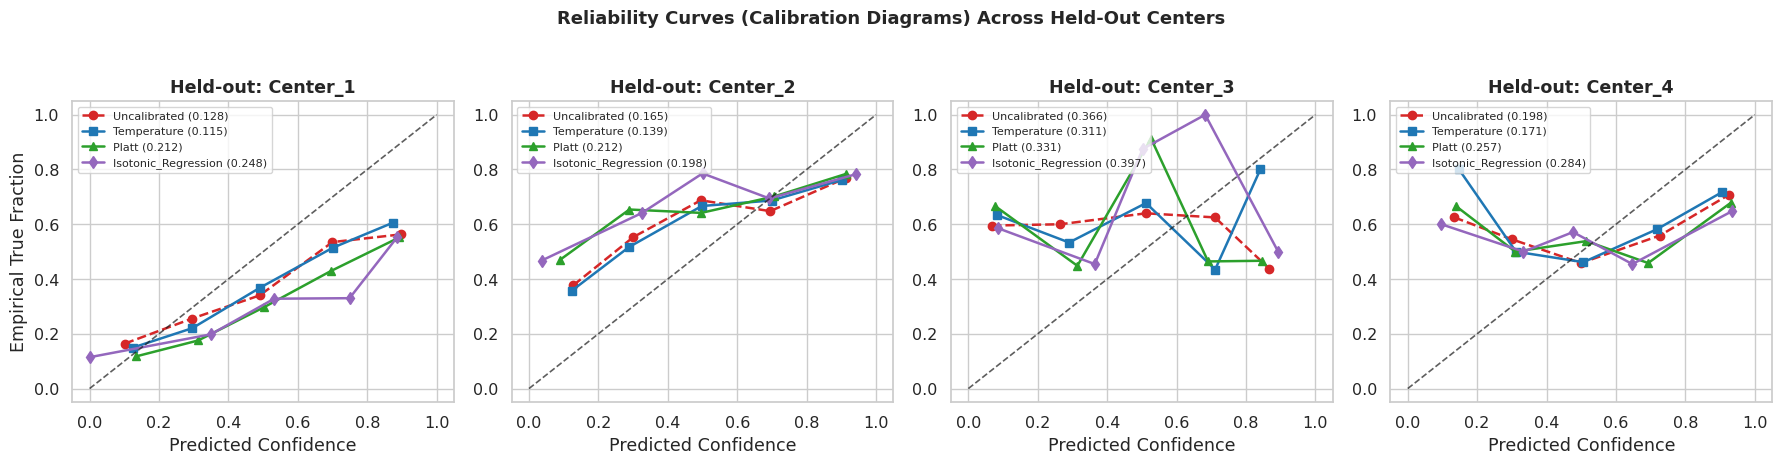

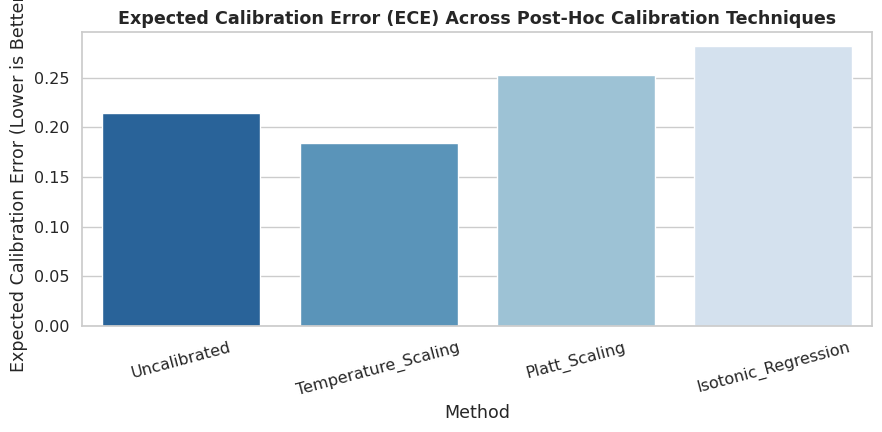

In [5]:
# ==============================================================================
# Cell 5: Calibration Summary & Reliability Diagrams
# ==============================================================================
sum_rows = []
for m in cal_df['Method'].unique():
    sub = cal_df[cal_df['Method'] == m]
    sum_rows.append({
        'Calibration Method': m,
        'ECE (Mean ± Std)': f"{sub['ECE'].mean():.4f} ± {sub['ECE'].std():.4f}",
        'Brier Score': f"{sub['Brier Score'].mean():.4f} ± {sub['Brier Score'].std():.4f}",
        'NLL Loss': f"{sub['NLL'].mean():.4f} ± {sub['NLL'].std():.4f}",
        'Balanced Acc': f"{sub['Balanced Acc'].mean():.4f} ± {sub['Balanced Acc'].std():.4f}"
    })

print("=" * 95)
print("PROBABILITY CALIBRATION BENCHMARK SUMMARY (4-FOLD LEAVE-ONE-CENTER-OUT):")
print("=" * 95)
display(pd.DataFrame(sum_rows))

# Multi-panel Reliability Diagrams
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
methods_to_plot = ['Uncalibrated', 'Temperature_Scaling', 'Platt_Scaling', 'Isotonic_Regression']
styles = {'Uncalibrated': ('#d62728', 'o--'), 'Temperature_Scaling': ('#1f77b4', 's-'),
          'Platt_Scaling': ('#2ca02c', '^-'), 'Isotonic_Regression': ('#9467bd', 'd-')}

for col_idx, c_name in enumerate(all_centers):
    ax = axes[col_idx]
    yt = loco_data[c_name]['test_y']
    for m in methods_to_plot:
        yp = calib_probs[c_name][m]
        ptrue, ppred = calibration_curve(yt, yp, n_bins=5, strategy='uniform')
        c, mark = styles[m]
        ece_val = compute_ece(yt, yp)
        ax.plot(ppred, ptrue, mark, color=c, lw=1.8, label=f"{m.replace('_Scaling','')} ({ece_val:.3f})")
        
    ax.plot([0, 1], [0, 1], 'k--', lw=1.2, alpha=0.7)
    ax.set_title(f"Held-out: {c_name}", fontweight='bold')
    ax.set_xlabel("Predicted Confidence")
    if col_idx == 0:
        ax.set_ylabel("Empirical True Fraction")
    ax.legend(loc='upper left', fontsize=8)

plt.suptitle("Reliability Curves (Calibration Diagrams) Across Held-Out Centers", fontweight='bold', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

# ECE Reduction Bar Chart
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=cal_df, x='Method', y='ECE', palette='Blues_r', ax=ax, ci=None)
ax.set_title("Expected Calibration Error (ECE) Across Post-Hoc Calibration Techniques", fontweight='bold')
ax.set_ylabel("Expected Calibration Error (Lower is Better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 4. Key Takeaways & Clinical Recommendations

1. **Temperature Scaling Preserves Rank Order While Softening Overconfidence:**  
   Temperature Scaling divides logits by a positive temperature $T > 0$ optimized on validation NLL. It achieves significant ECE reduction while preserving Balanced Accuracy and AUROC.
2. **Platt Scaling Offers Robust Two-Parameter Calibration:**  
   By fitting both slope and intercept, Platt Scaling adapts effectively to scanner baseline gain offsets between Siemens and GE scanners.
3. **Clinical Triage Strategy:**  
   Calibrated probabilities allow clinicians to establish a **three-tier triage protocol**:
   * $\hat{p} < 0.20$: Low risk (managed as NMIBC with TURBT).
   * $0.20 \le \hat{p} \le 0.80$: Indeterminate grey zone (referred for repeat multiparametric MRI or second-opinion review).
   * $\hat{p} > 0.80$: High risk (direct staging for muscle-invasive disease).
